AMNA ARIF

**Dataset:** `temperature_forecasting_dataset.csv` — 1,826 daily temperature readings (°C) from 1 Jan 2018 to 31 Dec 2022.

**Task:** look at the previous **30 days** of temperature and predict the temperature of the **next day**.

## 1. Load and inspect the data

Always look at data before modelling. We check the columns, the date range, missing values, gaps and duplicate dates.

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("./temperature_forecasting_dataset.csv", parse_dates=["date"])
print(df.head().to_string(index=False))
print()
print("Rows:", len(df), "| Columns:", list(df.columns))
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())

      date  temperature_c                data_type
2018-01-01           11.7 simulated_classroom_data
2018-01-02           10.4 simulated_classroom_data
2018-01-03           16.9 simulated_classroom_data
2018-01-04           14.8 simulated_classroom_data
2018-01-05            7.9 simulated_classroom_data

Rows: 1826 | Columns: ['date', 'temperature_c', 'data_type']
Date range: 2018-01-01 to 2022-12-31


In [47]:
# Data-quality checks
print("Missing values per column:")
print(df.isna().sum().to_string())
print()
print("Duplicate dates:", df["date"].duplicated().sum())
gaps = df["date"].diff().dropna().dt.days.value_counts()
print("Gap between consecutive rows (days: how many):", {int(k): int(v) for k, v in gaps.items()})
print("data_type values:", df["data_type"].unique().tolist())
print()
print(df["temperature_c"].describe().round(2).to_string())

assert df["date"].is_monotonic_increasing, "dates must be in chronological order"

Missing values per column:
date             0
temperature_c    0
data_type        0

Duplicate dates: 0
Gap between consecutive rows (days: how many): {1: 1825}
data_type values: ['simulated_classroom_data']

count    1826.00
mean       16.74
std         8.55
min        -2.00
25%         9.10
50%        17.05
75%        23.80
max        37.40


## 2. Exploring time series

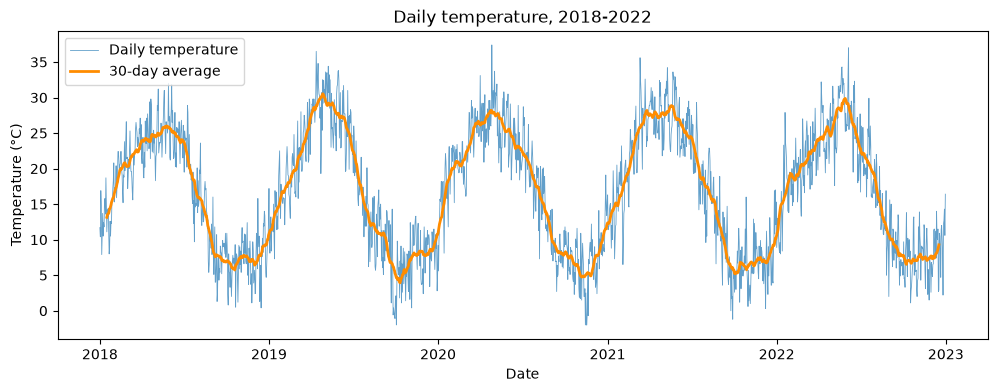

In [49]:
series = df.set_index("date")["temperature_c"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(series.index, series.values, lw=0.6, alpha=0.7, label="Daily temperature")
ax.plot(series.index, series.rolling(30, center=True).mean(), lw=2, color="darkorange",
        label="30-day average")
ax.set_title("Daily temperature, 2018-2022")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.legend()


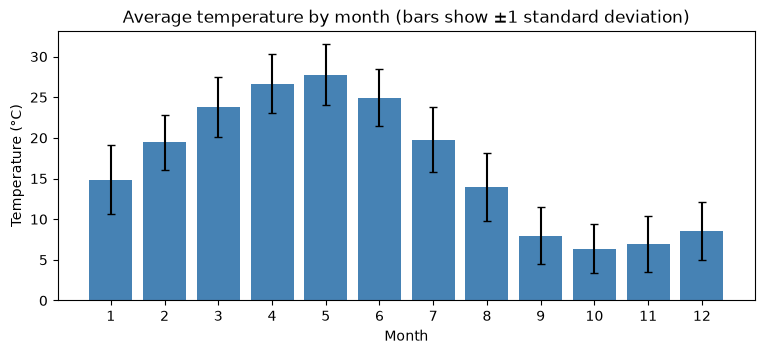

      mean  std
date           
1     14.9  4.2
2     19.4  3.4
3     23.8  3.7
4     26.7  3.6
5     27.8  3.8
6     25.0  3.5
7     19.8  4.0
8     14.0  4.1
9      8.0  3.5
10     6.4  3.0
11     6.9  3.5
12     8.6  3.6


In [50]:
# Seasonality: average temperature for each calendar month
monthly = series.groupby(series.index.month).agg(["mean", "std"])
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(monthly.index, monthly["mean"], yerr=monthly["std"], capsize=3, color="steelblue")
ax.set_xticks(range(1, 13))
ax.set_title("Average temperature by month (bars show ±1 standard deviation)")
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")
plt.show()
print(monthly.round(1).to_string())

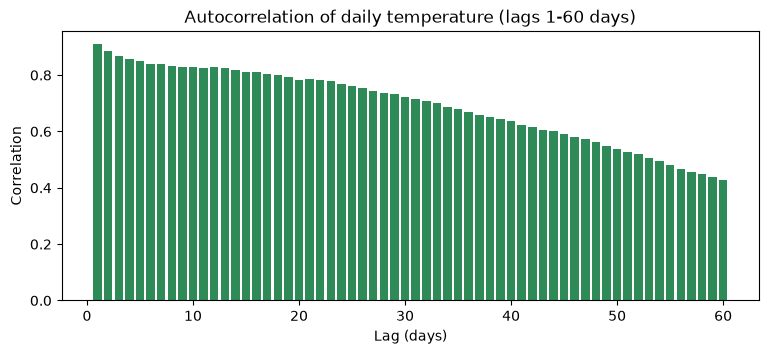

Lag 1 : 0.91
Lag 7 : 0.84
Lag 30: 0.72
Lag 365: 0.68


In [51]:
# Autocorrelation: how strongly is today's temperature related to the temperature k days earlier?
x = series.values - series.values.mean()
def autocorr(k):
    return np.dot(x[k:], x[:-k]) / np.dot(x, x)

lags = np.arange(1, 61)
acf = np.array([autocorr(k) for k in lags])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(lags, acf, color="seagreen")
ax.set_title("Autocorrelation of daily temperature (lags 1-60 days)")
ax.set_xlabel("Lag (days)")
ax.set_ylabel("Correlation")
plt.show()
print(f"Lag 1 : {autocorr(1):.2f}")
print(f"Lag 7 : {autocorr(7):.2f}")
print(f"Lag 30: {autocorr(30):.2f}")
print(f"Lag 365: {autocorr(365):.2f}")

exploration Result

1. **Strong yearly cycle.** Temperatures are low in winter and high in summer. This pattern repeats every year.
2. **Lots of day-to-day noise.** The daily readings jump around the smooth seasonal curve (the orange line).
3. **High autocorrelation.** Yesterday's temperature is strongly related to today's (about 0.9 at lag 1), and the relationship fades slowly. That is why *recent history* is a useful input and why a window of past days makes sense.

.

## 3. Split the data in chronological order

 The model must learn from the past and be tested on the future. The data has exactly five full years, so we split by year:

| Split | Period | Purpose |
|---|---|---|
| Training | 2018-2020 | Teach the model |
| Validation | 2021 | Choose settings and stop training at the right time |
| Test | 2022 | Final, untouched evaluation |

Each split contains at least one complete seasonal cycle, so every split covers both summer and winter.

Training:   2018-01-01 to 2020-12-31 (1096 days)
Validation: 2021-01-01 to 2021-12-31 (365 days)
Test:       2022-01-01 to 2022-12-31 (365 days)


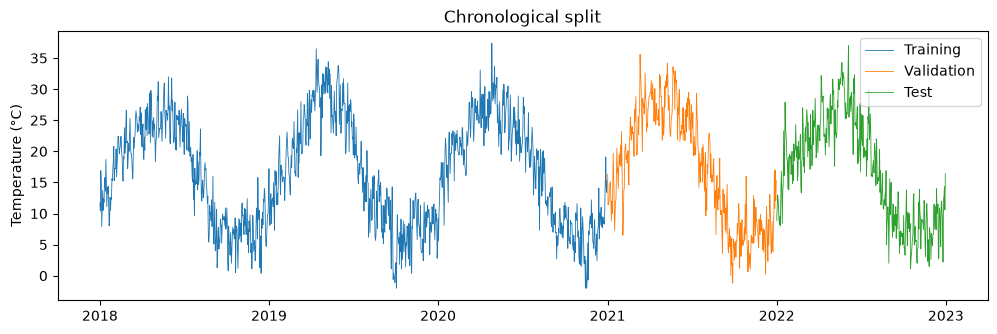

In [52]:
temps = df["temperature_c"].to_numpy(dtype="float64")
dates = df["date"].to_numpy()

train_end = int((df["date"] < "2021-01-01").sum())   # first index of 2021
val_end = int((df["date"] < "2022-01-01").sum())     # first index of 2022
n = len(temps)

print("Training:  ", df["date"].iloc[0].date(),         "to", df["date"].iloc[train_end - 1].date(), f"({train_end} days)")
print("Validation:", df["date"].iloc[train_end].date(), "to", df["date"].iloc[val_end - 1].date(),   f"({val_end - train_end} days)")
print("Test:      ", df["date"].iloc[val_end].date(),   "to", df["date"].iloc[-1].date(),            f"({n - val_end} days)")

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(df["date"][:train_end], temps[:train_end], lw=0.6, label="Training")
ax.plot(df["date"][train_end:val_end], temps[train_end:val_end], lw=0.6, label="Validation")
ax.plot(df["date"][val_end:], temps[val_end:], lw=0.6, label="Test")
ax.set_title("Chronological split")
ax.set_ylabel("Temperature (°C)")
ax.legend()
plt.show()

## 4. Scale the data (using training data only)

Neural networks train more smoothly when inputs are near zero with a spread near one:

$$x_{scaled}=\frac{x-\text{mean}_{train}}{\text{std}_{train}}$$

The mean and standard deviation come **only from the training period**. Using the whole dataset would let information from the validation and test years leak into preprocessing.

In [53]:
train_mean = temps[:train_end].mean()
train_std = temps[:train_end].std()
scaled = (temps - train_mean) / train_std

print(f"Training mean: {train_mean:.2f} °C | Training std: {train_std:.2f} °C")
print("First five values (°C):    ", np.round(temps[:5], 1))
print("First five values (scaled):", np.round(scaled[:5], 3))

def to_celsius(z):
    return z * train_std + train_mean

Training mean: 16.52 °C | Training std: 8.46 °C
First five values (°C):     [11.7 10.4 16.9 14.8  7.9]
First five values (scaled): [-0.57  -0.723  0.045 -0.203 -1.019]


## 5. Build sliding windows

We use the previous **30 days** to predict the next day:

```text
Input: days 1-30   -> target: day 31
Input: days 2-31   -> target: day 32
Input: days 3-32   -> target: day 33
```

The input shape is `(number of windows, 30 time steps, 1 feature)`.

A window may reach back into an earlier split for its *history* (the first validation target can use the last 30 training days as input). That is allowed because those days were already observed. The **target** always belongs to its own split.

In [54]:
WINDOW = 30

def make_windows(series, first_target, last_target_exclusive, window):
    X, y = [], []
    for i in range(first_target, last_target_exclusive):     # i = index of the day we predict
        X.append(series[i - window:i])                      # only days BEFORE i
        y.append(series[i])
    return np.array(X)[..., np.newaxis], np.array(y)

X_train, y_train = make_windows(scaled, WINDOW,    train_end, WINDOW)
X_val,   y_val   = make_windows(scaled, train_end, val_end,   WINDOW)
X_test,  y_test  = make_windows(scaled, val_end,   n,         WINDOW)

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   " y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  " y_test: ", y_test.shape)

# the 30 inputs end the day before the target.
i = val_end                      # first test target
print()
print("First test target date:", df["date"].iloc[i].date())
print("Last input date:       ", df["date"].iloc[i - 1].date())
print("Window covers:         ", df["date"].iloc[i - WINDOW].date(), "to", df["date"].iloc[i - 1].date())

X_train: (1066, 30, 1)  y_train: (1066,)
X_val:   (365, 30, 1)  y_val:   (365,)
X_test:  (365, 30, 1)  y_test:  (365,)

First test target date: 2022-01-01
Last input date:        2021-12-31
Window covers:          2021-12-02 to 2021-12-31


In [55]:
def metrics(actual_c, predicted_c):
    err = actual_c - predicted_c
    return float(np.mean(np.abs(err))), float(np.sqrt(np.mean(err ** 2)))

# Targets in original units for validation and test
y_val_c, y_test_c = to_celsius(y_val), to_celsius(y_test)

def last_k_mean(X, k):
    return X[:, -k:, 0].mean(axis=1)

# Ridge regression on the 30-day window (closed form), fitted on training data only
def fit_ridge(X, y, alpha=1.0):
    A = np.hstack([X[:, :, 0], np.ones((len(X), 1))])
    reg = alpha * np.eye(A.shape[1]); reg[-1, -1] = 0           # do not penalise the intercept
    return np.linalg.solve(A.T @ A + reg, A.T @ y)

def predict_ridge(w, X):
    return np.hstack([X[:, :, 0], np.ones((len(X), 1))]) @ w

ridge_w = fit_ridge(X_train, y_train, alpha=10.0)

baseline_preds = {
    "Persistence (yesterday)": {"val": to_celsius(last_k_mean(X_val, 1)),  "test": to_celsius(last_k_mean(X_test, 1))},
    "3-day average":           {"val": to_celsius(last_k_mean(X_val, 3)),  "test": to_celsius(last_k_mean(X_test, 3))},
    "7-day average":           {"val": to_celsius(last_k_mean(X_val, 7)),  "test": to_celsius(last_k_mean(X_test, 7))},
    "Linear model (30 days)":  {"val": to_celsius(predict_ridge(ridge_w, X_val)), "test": to_celsius(predict_ridge(ridge_w, X_test))},
}

rows = []
for name, p in baseline_preds.items():
    v_mae, v_rmse = metrics(y_val_c, p["val"])
    t_mae, t_rmse = metrics(y_test_c, p["test"])
    rows.append([name, v_mae, v_rmse, t_mae, t_rmse])

baseline_table = pd.DataFrame(rows, columns=["Method", "Val MAE", "Val RMSE", "Test MAE", "Test RMSE"]).set_index("Method")
print(baseline_table.round(3).to_string())

                         Val MAE  Val RMSE  Test MAE  Test RMSE
Method                                                         
Persistence (yesterday)    2.900     3.592     2.988      3.846
3-day average              2.754     3.484     2.795      3.607
7-day average              2.982     3.719     2.855      3.639
Linear model (30 days)     2.570     3.259     2.572      3.301


**Read this table carefully.** Because daily readings are noisy, even the simplest methods are off by roughly 3 °C on a typical day. The differences between baselines are small. Any model, including an RNN, will also be limited by the noise: the leftover unpredictable part of each day.

In [56]:
class SimpleRNNRegressor:
    # Many-to-one RNN: reads a window of inputs, predicts one number.

    def __init__(self, hidden_size=16, seed=42):
        rng = np.random.default_rng(seed)
        H = hidden_size
        self.H = H
        self.params = {
            "Wx": rng.normal(0, 0.5, (1, H)),
            "Wh": rng.normal(0, 1.0 / np.sqrt(H), (H, H)) * 0.8,
            "b":  np.zeros(H),
            "Wo": rng.normal(0, 1.0 / np.sqrt(H), (H, 1)),
            "bo": np.zeros(1),
        }

    def forward(self, X):
        # X has shape (B, T, 1). Returns predictions (B,) and the cache needed for backprop.
        p = self.params
        B, T, _ = X.shape
        h = np.zeros((B, self.H))
        hs = [h]                                   # hs[0] is h_0; hs[t] is the state after step t
        for t in range(T):
            h = np.tanh(X[:, t, :] @ p["Wx"] + h @ p["Wh"] + p["b"])
            hs.append(h)
        y_hat = (h @ p["Wo"] + p["bo"])[:, 0]
        return y_hat, (X, hs)

    def loss_and_grads(self, X, y):
        p = self.params
        y_hat, (X, hs) = self.forward(X)
        B, T, _ = X.shape
        loss = np.mean((y_hat - y) ** 2)

        grads = {k: np.zeros_like(v) for k, v in p.items()}
        d_out = (2.0 / B) * (y_hat - y)[:, None]              # dL/dy_hat, shape (B, 1)
        grads["Wo"] = hs[-1].T @ d_out
        grads["bo"] = d_out.sum(axis=0)

        dh = d_out @ p["Wo"].T                                 # gradient arriving at h_T
        for t in range(T, 0, -1):                              # backpropagation through time
            da = dh * (1.0 - hs[t] ** 2)                       # through tanh
            grads["Wx"] += X[:, t - 1, :].T @ da
            grads["Wh"] += hs[t - 1].T @ da
            grads["b"]  += da.sum(axis=0)
            dh = da @ p["Wh"].T                                # pass the error one step back
        return loss, grads

    def predict(self, X, batch_size=512):
        out = [self.forward(X[i:i + batch_size])[0] for i in range(0, len(X), batch_size)]
        return np.concatenate(out)

    def n_parameters(self):
        return sum(v.size for v in self.params.values())


class Adam:
    # Adam optimiser: gradient descent with moving averages of the gradient and its square.
    def __init__(self, params, lr=0.003, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps, self.t = lr, beta1, beta2, eps, 0
        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}

    def step(self, params, grads):
        self.t += 1
        for k in params:
            self.m[k] = self.b1 * self.m[k] + (1 - self.b1) * grads[k]
            self.v[k] = self.b2 * self.v[k] + (1 - self.b2) * grads[k] ** 2
            m_hat = self.m[k] / (1 - self.b1 ** self.t)
            v_hat = self.v[k] / (1 - self.b2 ** self.t)
            params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)


def clip_gradients(grads, max_norm=1.0):
    # Rescale all gradients if their combined size is too large (helps keep RNN training stable).
    total = np.sqrt(sum(np.sum(g ** 2) for g in grads.values()))
    if total > max_norm:
        for k in grads:
            grads[k] *= max_norm / total
    return total

demo = SimpleRNNRegressor(hidden_size=16)
print("Number of learnable parameters:", demo.n_parameters())
print("  Wx 1x16 =", 16, "| Wh 16x16 =", 256, "| b =", 16, "| Wo 16x1 =", 16, "| bo =", 1)

Number of learnable parameters: 305
  Wx 1x16 = 16 | Wh 16x16 = 256 | b = 16 | Wo 16x1 = 16 | bo = 1


### Check the backward pass with numerical gradients

Backpropagation code is easy to get subtly wrong. A **gradient check** compares our analytic gradients against a slow but simple numerical estimate: nudge one parameter up and down by a tiny amount `ε` and see how the loss changes.

$$\frac{\partial L}{\partial \theta}\approx\frac{L(\theta+\varepsilon)-L(\theta-\varepsilon)}{2\varepsilon}$$

If the relative difference is tiny (around 1e-7 or smaller), the backward pass is correct.

In [57]:
def gradient_check(model, X, y, eps=1e-6, checks_per_param=6, seed=0):
    rng = np.random.default_rng(seed)
    _, analytic = model.loss_and_grads(X, y)
    worst = 0.0
    for name, value in model.params.items():
        flat = value.reshape(-1)                      # a view: editing flat edits the parameter
        idx = rng.choice(flat.size, size=min(checks_per_param, flat.size), replace=False)
        for j in idx:
            original = flat[j]
            flat[j] = original + eps; loss_plus, _ = model.loss_and_grads(X, y)
            flat[j] = original - eps; loss_minus, _ = model.loss_and_grads(X, y)
            flat[j] = original
            numeric = (loss_plus - loss_minus) / (2 * eps)
            a = analytic[name].reshape(-1)[j]
            rel = abs(a - numeric) / max(1e-12, abs(a) + abs(numeric))
            worst = max(worst, rel)
    return worst

check_model = SimpleRNNRegressor(hidden_size=8, seed=1)
worst_rel_error = gradient_check(check_model, X_train[:16, :10], y_train[:16])
print(f"Largest relative difference between analytic and numerical gradients: {worst_rel_error:.2e}")
print("Backward pass is correct." if worst_rel_error < 1e-5 else "Mismatch - check the backward pass!")

Largest relative difference between analytic and numerical gradients: 8.35e-09
Backward pass is correct.


## 8. Train the model

One training step on a mini-batch:

1. **Forward pass** → predictions
2. **Loss** → how wrong they are
3. **BPTT** → gradients for every parameter
4. **Clip** the gradients if they are very large
5. **Adam update** → move the parameters a small step to reduce the loss

An **epoch** is one pass through all training windows (shuffled into mini-batches of 32). Shuffling the *windows* inside the training set is fine, because each window already contains its own history in the correct order. After each epoch we measure the validation loss and keep the best weights (**early stopping**).

In [58]:
def train_model(hidden_size=16, lr=0.003, epochs=80, batch_size=32, patience=10, seed=42, verbose=True,
                X_tr=None, y_tr=None, X_va=None, y_va=None):
    X_tr = X_train if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    X_va = X_val if X_va is None else X_va
    y_va = y_val if y_va is None else y_va

    model = SimpleRNNRegressor(hidden_size=hidden_size, seed=seed)
    opt = Adam(model.params, lr=lr)
    rng = np.random.default_rng(seed)

    history = {"train_loss": [], "val_loss": []}
    best_val, best_params, best_epoch, waited = np.inf, None, 0, 0

    for epoch in range(1, epochs + 1):
        order = rng.permutation(len(X_tr))
        batch_losses = []
        for start in range(0, len(X_tr), batch_size):
            idx = order[start:start + batch_size]
            loss, grads = model.loss_and_grads(X_tr[idx], y_tr[idx])
            clip_gradients(grads, max_norm=1.0)
            opt.step(model.params, grads)
            batch_losses.append(loss)

        train_loss = float(np.mean(batch_losses))
        val_loss = float(np.mean((model.predict(X_va) - y_va) ** 2))
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val - 1e-5:
            best_val, best_epoch, waited = val_loss, epoch, 0
            best_params = {k: v.copy() for k, v in model.params.items()}
        else:
            waited += 1

        if verbose and (epoch == 1 or epoch % 5 == 0):
            print(f"Epoch {epoch:3d} | train loss {train_loss:.4f} | val loss {val_loss:.4f}")
        if waited >= patience:
            if verbose:
                print(f"Early stopping at epoch {epoch}: no validation improvement for {patience} epochs.")
            break

    model.params = best_params                 # restore the best weights
    history["best_epoch"] = best_epoch
    if verbose:
        print(f"Best epoch: {best_epoch} (validation loss {best_val:.4f}, scaled units)")
    return model, history

rnn, history = train_model()

Epoch   1 | train loss 0.1532 | val loss 0.1537
Epoch   5 | train loss 0.1419 | val loss 0.1487
Epoch  10 | train loss 0.1375 | val loss 0.1500
Epoch  15 | train loss 0.1408 | val loss 0.1457
Epoch  20 | train loss 0.1349 | val loss 0.1451
Epoch  25 | train loss 0.1343 | val loss 0.1509
Epoch  30 | train loss 0.1377 | val loss 0.1550
Early stopping at epoch 30: no validation improvement for 10 epochs.
Best epoch: 20 (validation loss 0.1451, scaled units)


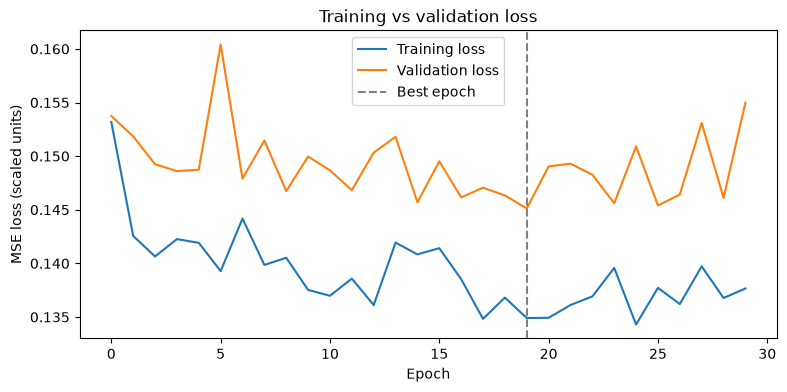

In [59]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(history["train_loss"], label="Training loss")
ax.plot(history["val_loss"], label="Validation loss")
ax.axvline(history["best_epoch"] - 1, color="gray", ls="--", label="Best epoch")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE loss (scaled units)")
ax.set_title("Training vs validation loss")
ax.legend()
plt.show()

**How to read the curves:** the training loss falls as the model fits the training years. The validation loss shows how it does on a year it never trained on. Training stops once validation loss stops improving, and the weights from the best epoch are kept. If the validation curve rose while the training curve kept falling, that would be **overfitting**.

Note that both losses stay well above zero. That is the unpredictable daily noise.

## 9. Evaluate on the test year (2022)

The test year was not used for training, scaling, or choosing when to stop. We convert predictions back to °C and compare with every baseline.

In [60]:
pred_val_c  = to_celsius(rnn.predict(X_val))
pred_test_c = to_celsius(rnn.predict(X_test))

results = baseline_table.copy()
v_mae, v_rmse = metrics(y_val_c, pred_val_c)
t_mae, t_rmse = metrics(y_test_c, pred_test_c)
results.loc["RNN (16 hidden units)"] = [v_mae, v_rmse, t_mae, t_rmse]
results = results.sort_values("Test MAE")
print(results.round(3).to_string())

best_name = results.index[0]
rnn_rank = list(results.index).index("RNN (16 hidden units)") + 1
print()
print(f"Best on test MAE: {best_name}")
print(f"The RNN ranks #{rnn_rank} of {len(results)} on test MAE.")

                         Val MAE  Val RMSE  Test MAE  Test RMSE
Method                                                         
Linear model (30 days)     2.570     3.259     2.572      3.301
RNN (16 hidden units)      2.563     3.223     2.629      3.395
3-day average              2.754     3.484     2.795      3.607
7-day average              2.982     3.719     2.855      3.639
Persistence (yesterday)    2.900     3.592     2.988      3.846

Best on test MAE: Linear model (30 days)
The RNN ranks #2 of 5 on test MAE.


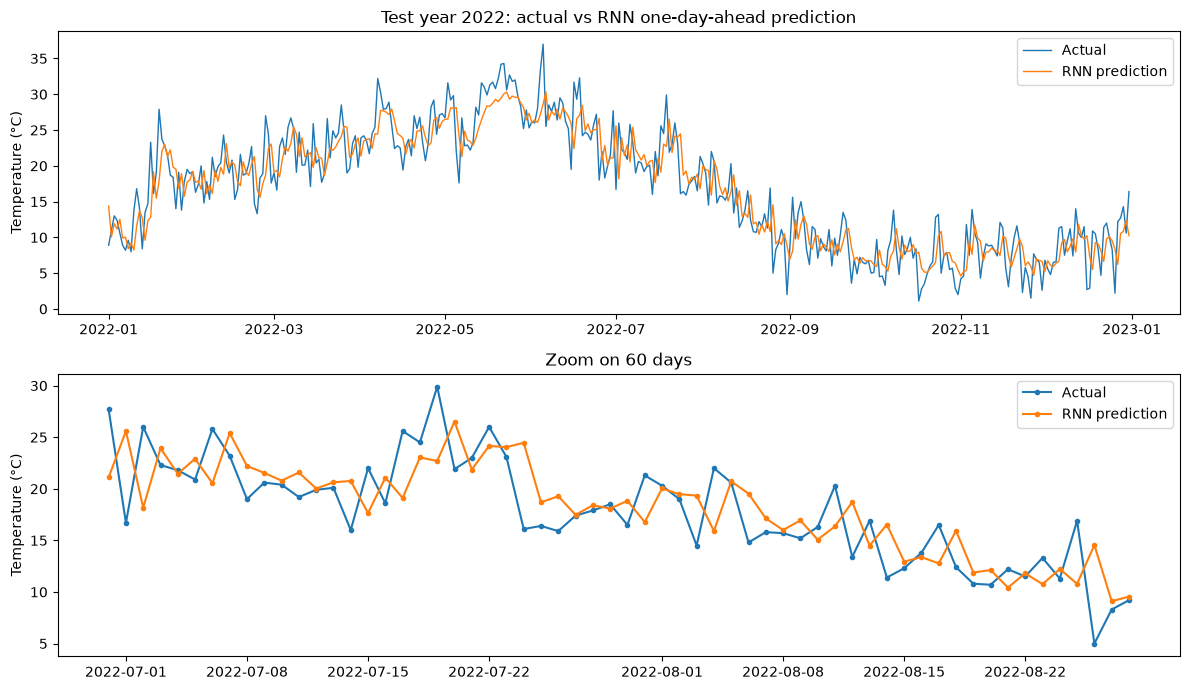

In [61]:
test_dates = df["date"].iloc[val_end:].to_numpy()

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(test_dates, y_test_c, lw=1, label="Actual")
axes[0].plot(test_dates, pred_test_c, lw=1, label="RNN prediction")
axes[0].set_title("Test year 2022: actual vs RNN one-day-ahead prediction")
axes[0].set_ylabel("Temperature (°C)")
axes[0].legend()

zoom = slice(180, 240)       # a 60-day stretch in mid-summer
axes[1].plot(test_dates[zoom], y_test_c[zoom], "o-", ms=3, label="Actual")
axes[1].plot(test_dates[zoom], pred_test_c[zoom], "o-", ms=3, label="RNN prediction")
axes[1].set_title("Zoom on 60 days")
axes[1].set_ylabel("Temperature (°C)")
axes[1].legend()
plt.tight_layout()
plt.show()

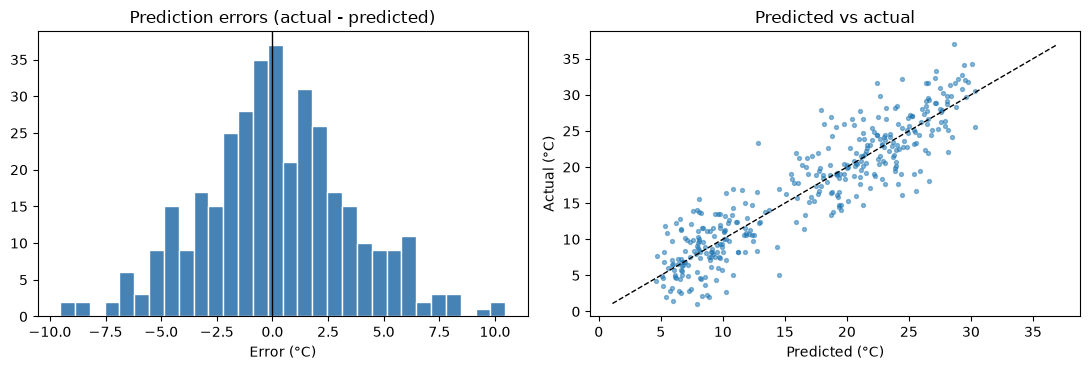

Mean error (bias): +0.18 °C
Share of days within ±2 °C: 48%
Share of days within ±4 °C: 76%


In [62]:
errors = y_test_c - pred_test_c

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(errors, bins=30, color="steelblue", edgecolor="white")
axes[0].axvline(0, color="k", lw=1)
axes[0].set_title("Prediction errors (actual - predicted)")
axes[0].set_xlabel("Error (°C)")

axes[1].scatter(pred_test_c, y_test_c, s=8, alpha=0.5)
lims = [min(pred_test_c.min(), y_test_c.min()), max(pred_test_c.max(), y_test_c.max())]
axes[1].plot(lims, lims, "k--", lw=1)
axes[1].set_title("Predicted vs actual")
axes[1].set_xlabel("Predicted (°C)")
axes[1].set_ylabel("Actual (°C)")
plt.tight_layout()
plt.show()

print(f"Mean error (bias): {errors.mean():+.2f} °C")
print(f"Share of days within ±2 °C: {np.mean(np.abs(errors) <= 2):.0%}")
print(f"Share of days within ±4 °C: {np.mean(np.abs(errors) <= 4):.0%}")

### How to interpret the results honestly

- Compare the RNN's test MAE with the baselines **in the table above**, not with zero. The question is whether it adds value over a simple method.
- If the RNN, the linear model and the short averages are all close, the data simply does not contain much more predictable structure than they already capture. Most of the remaining error is random day-to-day noise.
- A model with a small advantage on one test year does not prove it is better in general. A different random seed or a different year could change the order of close competitors.
- This is simulated classroom data. It shows how the workflow behaves; it says nothing about real weather forecasting skill.

## 10. Look inside: what does the hidden state do?

The hidden state is a vector of 16 numbers that changes as the RNN reads the 30 days. Each unit is a different learned summary. Below, we feed one test window through the network and plot how a few hidden units evolve, next to the input.

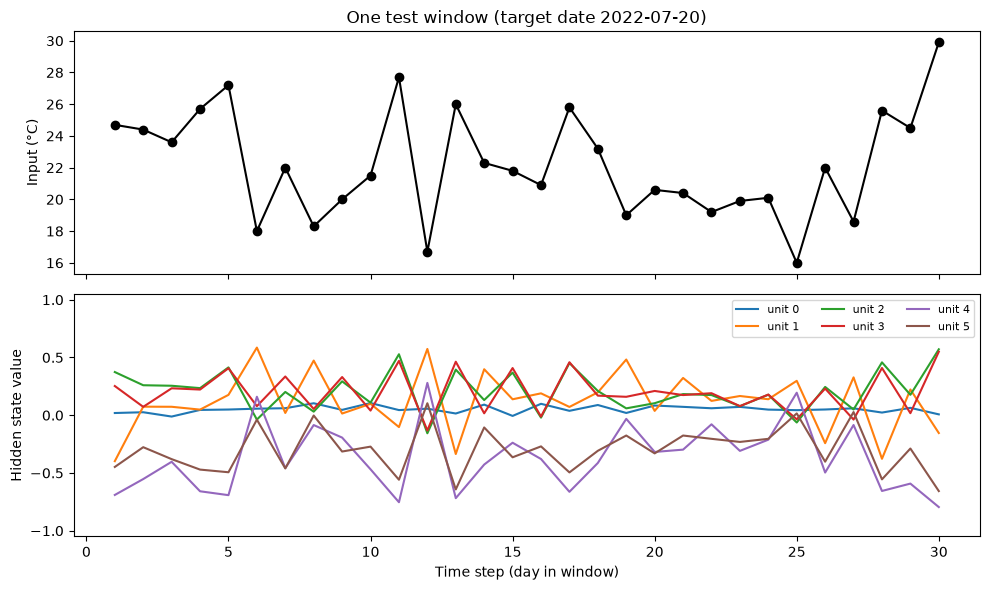

All hidden values stay between -1 and +1 because tanh squashes them.
Prediction for this window: 26.52 °C | actual: 21.90 °C


In [63]:
window_idx = 200
xw = X_test[window_idx:window_idx + 1]
_, (_, hs) = rnn.forward(xw)
hidden_over_time = np.array([h[0] for h in hs[1:]])        # shape (30, 16)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(range(1, WINDOW + 1), to_celsius(xw[0, :, 0]), "o-", color="black")
axes[0].set_ylabel("Input (°C)")
axes[0].set_title(f"One test window (target date {df['date'].iloc[val_end + window_idx].date()})")

for u in range(6):
    axes[1].plot(range(1, WINDOW + 1), hidden_over_time[:, u], label=f"unit {u}")
axes[1].set_xlabel("Time step (day in window)")
axes[1].set_ylabel("Hidden state value")
axes[1].set_ylim(-1.05, 1.05)
axes[1].legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()
print("All hidden values stay between -1 and +1 because tanh squashes them.")
print(f"Prediction for this window: {to_celsius(rnn.predict(xw)[0]):.2f} °C | actual: {y_test_c[window_idx]:.2f} °C")

## 11. Forecasting further ahead

So far every prediction used 30 *real* days. To look several days ahead we can feed the model's own prediction back in as the newest input (a **recursive forecast**). Errors then build up, because later steps rely on earlier guesses. We test this on the 2022 data for horizons of 1 to 7 days and compare with two simple baselines.

            RNN MAE  Persistence MAE  7-day average MAE
Days ahead                                             
1              2.60             2.96               2.83
2              2.88             3.46               3.07
3              3.04             3.68               3.23
4              3.09             3.72               3.32
5              3.24             3.79               3.44
6              3.28             3.99               3.48
7              3.35             4.10               3.54


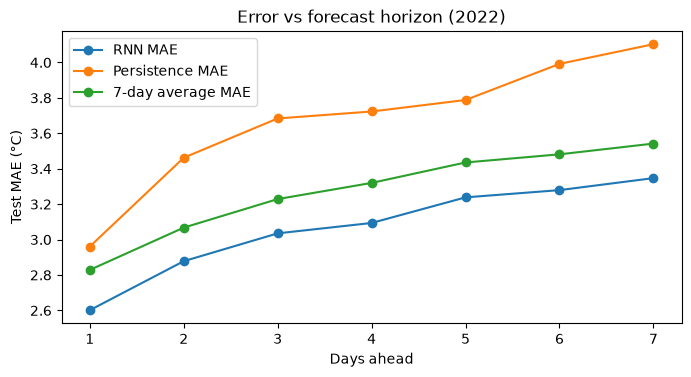

In [64]:
def recursive_forecast(model, X, horizon):
    window = X.copy()
    preds = []
    for _ in range(horizon):
        p = model.predict(window)
        preds.append(p)
        window = np.concatenate([window[:, 1:, :], p[:, None, None]], axis=1)   # drop oldest, add prediction
    return np.stack(preds, axis=1)                                              # (windows, horizon)

HORIZON = 7
starts = np.arange(val_end, n - HORIZON + 1)                       # every 2022 day that has 7 future days
Xh = np.stack([scaled[i - WINDOW:i] for i in starts])[..., None]
truth = np.stack([temps[i:i + HORIZON] for i in starts])            # (windows, 7) in °C

rnn_h = to_celsius(recursive_forecast(rnn, Xh, HORIZON))
persist_h = np.repeat(to_celsius(Xh[:, -1, 0])[:, None], HORIZON, axis=1)
avg7_h = np.repeat(to_celsius(Xh[:, -7:, 0].mean(axis=1))[:, None], HORIZON, axis=1)

rows = []
for h in range(HORIZON):
    rows.append([h + 1,
                 np.abs(truth[:, h] - rnn_h[:, h]).mean(),
                 np.abs(truth[:, h] - persist_h[:, h]).mean(),
                 np.abs(truth[:, h] - avg7_h[:, h]).mean()])
horizon_table = pd.DataFrame(rows, columns=["Days ahead", "RNN MAE", "Persistence MAE", "7-day average MAE"]).set_index("Days ahead")
print(horizon_table.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
for col in horizon_table.columns:
    ax.plot(horizon_table.index, horizon_table[col], "o-", label=col)
ax.set_xlabel("Days ahead")
ax.set_ylabel("Test MAE (°C)")
ax.set_title("Error vs forecast horizon (2022)")
ax.legend()
plt.show()

Forecasting multiple days ahead is harder than one day ahead, and the error generally grows with the horizon. Whether the RNN is better or worse than the baselines at longer horizons is something you can read directly from the table, not something to assume.

Note that the 1-day-ahead row can differ slightly from the Section 9 result, because here we only use start days that still have 7 full days of truth after them (the last 6 days of 2022 are left out).

## 12. Predict the next day

The data ends on 31 December 2022. We feed the last 30 days into the model and ask for 1 January 2023. Remember the typical error from the test results: the answer is an estimate, not a guarantee.

In [65]:
latest_window = scaled[-WINDOW:].reshape(1, WINDOW, 1)
next_day_c = to_celsius(rnn.predict(latest_window)[0])

print(f"Last observed day: {df['date'].iloc[-1].date()}  ->  {temps[-1]:.1f} °C")
print(f"Predicted temperature for {(df['date'].iloc[-1] + pd.Timedelta(days=1)).date()}: {next_day_c:.1f} °C")
print(f"Typical error on the test year (MAE): about ±{t_mae:.1f} °C")

Last observed day: 2022-12-31  ->  16.4 °C
Predicted temperature for 2023-01-01: 14.4 °C
Typical error on the test year (MAE): about ±2.6 °C


## 13. Experiments

Change **one setting at a time**, predict what will happen, then compare. Selection uses the **validation** MAE. We report test MAE for information, but we do not tune on it, otherwise the test year stops being an honest final exam.

The helper below rebuilds the windows for a given window length, trains a model, and returns both errors.

In [66]:
def run_experiment(window=30, hidden_size=16, lr=0.003, seed=42):
    Xtr, ytr = make_windows(scaled, window,    train_end, window)
    Xva, yva = make_windows(scaled, train_end, val_end,   window)
    Xte, yte = make_windows(scaled, val_end,   n,         window)
    m, h = train_model(hidden_size=hidden_size, lr=lr, seed=seed, verbose=False,
                       X_tr=Xtr, y_tr=ytr, X_va=Xva, y_va=yva)
    v = metrics(to_celsius(yva), to_celsius(m.predict(Xva)))[0]
    t = metrics(to_celsius(yte), to_celsius(m.predict(Xte)))[0]
    return v, t, h["best_epoch"]

settings = [
    ("Baseline setting",       dict(window=30, hidden_size=16, lr=0.003)),
    ("Shorter window (7)",     dict(window=7,  hidden_size=16, lr=0.003)),
    ("Shorter window (14)",    dict(window=14, hidden_size=16, lr=0.003)),
    ("Longer window (60)",     dict(window=60, hidden_size=16, lr=0.003)),
    ("Fewer hidden units (4)", dict(window=30, hidden_size=4,  lr=0.003)),
    ("More hidden units (32)", dict(window=30, hidden_size=32, lr=0.003)),
    ("Lower learning rate",    dict(window=30, hidden_size=16, lr=0.0005)),
]

rows = []
for label, kw in settings:
    v, t, e = run_experiment(**kw)
    rows.append([label, v, t, e])
exp_table = pd.DataFrame(rows, columns=["Setting", "Val MAE", "Test MAE", "Best epoch"]).set_index("Setting")
print(exp_table.round(3).to_string())
print()
print("Best validation MAE:", exp_table["Val MAE"].idxmin())


                        Val MAE  Test MAE  Best epoch
Setting                                              
Baseline setting          2.563     2.629          20
Shorter window (7)        2.564     2.633          16
Shorter window (14)       2.539     2.632          39
Longer window (60)        2.543     2.616          43
Fewer hidden units (4)    2.547     2.647          76
More hidden units (32)    2.549     2.677          10
Lower learning rate       2.541     2.618          78

Best validation MAE: Shorter window (14)


### Seed check: how much is just luck?

A neural network starts from random weights. Training the same setting with different seeds shows how much of a difference between two settings could simply be luck.

In [67]:
seed_rows = []
for s in range(5):
    v, t, e = run_experiment(window=30, hidden_size=16, lr=0.003, seed=s)
    seed_rows.append([s, v, t])
seed_table = pd.DataFrame(seed_rows, columns=["Seed", "Val MAE", "Test MAE"]).set_index("Seed")
print(seed_table.round(3).to_string())
print()
print(f"Test MAE across seeds: mean {seed_table['Test MAE'].mean():.3f}, "
      f"min {seed_table['Test MAE'].min():.3f}, max {seed_table['Test MAE'].max():.3f}")
print("If two settings differ by less than this spread, do not read much into the difference.")

      Val MAE  Test MAE
Seed                   
0       2.545     2.704
1       2.539     2.640
2       2.510     2.722
3       2.556     2.640
4       2.545     2.676

Test MAE across seeds: mean 2.676, min 2.640, max 2.722
If two settings differ by less than this spread, do not read much into the difference.


## 14. Basic RNN vs LSTM vs GRU

A basic RNN reuses one hidden-state update at every step. For long sequences, the gradient can shrink (or grow) as it is multiplied through many steps, so a basic RNN struggles to learn effects far back in time.

- **LSTM** adds a separate cell state and gates that decide what to keep, write and expose.
- **GRU** is a lighter gated version.

Here the useful information is mostly in the last few days (autocorrelation fades within a couple of weeks), and the yearly cycle is much longer than a 30-day window, so a gated network has less to gain than it would on a problem with truly long-range structure. Treat it as an experiment, not as a guaranteed improvement.

Once TensorFlow or PyTorch works on your machine you can swap in `LSTM(16)` or `GRU(16)` in place of `SimpleRNN(16)` and compare against the table in Section 9.

## 15. Common mistakes (specific to this dataset)

1. **Shuffling the days before splitting.** The test year would then contain days surrounded by training days, which makes results look better than reality.
2. **Scaling with the whole dataset.** Use training-year statistics only.
3. **Skipping the baselines.** Without them, "MAE of 3 °C" means nothing.
4. **Tuning on the test year.** Choose settings with the validation year; look at the test year once.
5. **Judging by one run.** Check several seeds before claiming one setting beats another.
6. **Forgetting the noise.** A big part of the error cannot be removed by any model.
7. **Confusing hidden size with window length.** 16 hidden units does not mean 16 days.
8. **Over-trusting simulated data.** Good results here do not transfer to real weather.
9. **Trusting multi-day recursive forecasts as much as one-day forecasts.** Errors accumulate.



**Activity A**
1. Summer months (around June–August) are warmest and winter months (around December–February) are coldest; the monthly bar chart shows it.
2. Consecutive days are very similar, so recent days are informative for predicting tomorrow.
3. The window only sees a month, so it cannot see a whole year. For next-day prediction that is fine, because the recent days already carry the seasonal level; the yearly cycle matters more for forecasts months ahead.

**Activity B**
$h_1=\tanh(0.5\times2)=\tanh(1)\approx0.762$ and $h_2=\tanh(0.5\times3+0.5\times0.762)=\tanh(1.881)\approx0.955$. The state $h_1$ carries information from the first input into the second step.

**Activity C** Results depend on random initialisation and settings, so use your own run's tables. Compare the gap between settings with the seed spread before declaring a winner.

**Activity D**
1. Not necessarily a failure. It means the data is noisy and simple methods capture most of the predictable part. For a real project, prefer the simplest model that performs about as well (easier to maintain and explain), and test on real data.
2. The data is artificially generated with its own noise pattern; real weather has changing conditions and unexpected events.

**Activity E** The mean and standard deviation then include information from the validation and test years (data leakage). It can make the test error look slightly more optimistic than it would be in real forecasting, where the future is unknown.

## 16. Predict a chosen date from the dataset

The model now reads its input **directly from the dataset**. You only type a **date**. The notebook takes the 30 days before it, predicts, and, when the real temperature is in the dataset, **evaluates** the prediction against it.

**What you can do**

1. Enter a date inside the dataset (for example `2022-07-15`). The model predicts that day from the 30 days before it, and the result is compared with the real value.
2. Or enter a date after the last data day (up to 7 days after 2022-12-31). The model predicts it from the last 30 days of the dataset. No real value exists yet, so there is nothing to compare.
3. Press Enter to predict the next day after the dataset.

**How the evaluation works**

- The *expected range* comes from the model's errors on the **validation year (2021)**, separately for each horizon, so the 2022 test year stays untouched. It is the range that contained the middle 80% of validation errors.
- The *typical error* is the MAE on the same validation year.
- For an honest evaluation choose a date in **2022**. Earlier dates were used for training or validation, so the model has already seen them.

> The model only knows **temperature history**. The dataset has no other columns (such as elevation, humidity or location), so it cannot predict anything else.


In [68]:
# Error profile per forecast horizon, measured on the VALIDATION year only
MAX_H = 7
val_starts = np.arange(train_end, val_end - MAX_H + 1)
Xv_h = np.stack([scaled[i - WINDOW:i] for i in val_starts])[..., None]
truth_v = np.stack([temps[i:i + MAX_H] for i in val_starts])
pred_v = to_celsius(recursive_forecast(rnn, Xv_h, MAX_H))
val_err_h = truth_v - pred_v                                   # (windows, 7), actual - predicted

error_profile = pd.DataFrame({
    "Typical error (MAE)": np.abs(val_err_h).mean(axis=0),
    "Range low":  np.percentile(val_err_h, 10, axis=0),
    "Range high": np.percentile(val_err_h, 90, axis=0),
}, index=pd.Index(range(1, MAX_H + 1), name="Days ahead"))
print("Error profile of the RNN on the validation year (2021):")
print(error_profile.round(2).to_string())

# Honest check: does the 80% range also hold on the untouched test year?
test_starts = np.arange(val_end, n - MAX_H + 1)
Xt_h = np.stack([scaled[i - WINDOW:i] for i in test_starts])[..., None]
truth_t = np.stack([temps[i:i + MAX_H] for i in test_starts])
err_t = truth_t - to_celsius(recursive_forecast(rnn, Xt_h, MAX_H))
inside = [np.mean((err_t[:, h] >= error_profile["Range low"].iloc[h]) &
                  (err_t[:, h] <= error_profile["Range high"].iloc[h])) for h in range(MAX_H)]
print()
print("Share of 2022 test days that fell inside the expected range (aim: about 80%):")
print({h + 1: f"{p:.0%}" for h, p in enumerate(inside)})


Error profile of the RNN on the validation year (2021):
            Typical error (MAE)  Range low  Range high
Days ahead                                            
1                          2.53      -4.05        3.89
2                          2.89      -4.82        4.56
3                          3.10      -4.85        5.22
4                          3.25      -4.79        5.99
5                          3.34      -4.93        6.02
6                          3.40      -4.93        6.09
7                          3.40      -4.98        6.12

Share of 2022 test days that fell inside the expected range (aim: about 80%):
{1: '76%', 2: '78%', 3: '81%', 4: '82%', 5: '85%', 6: '84%', 7: '82%'}


In [70]:
def forecast_from_temperatures(last_temps, days_ahead=1, actual=None):
    """Predict the temperature `days_ahead` days after the given 30 daily readings (°C, oldest first).
    If `actual` (°C) is given, also evaluate the prediction for the target day."""
    last_temps = np.asarray(last_temps, dtype="float64")
    if last_temps.shape != (WINDOW,):
        raise ValueError(f"Need exactly {WINDOW} temperatures, got {last_temps.size}.")
    if not np.all(np.isfinite(last_temps)):
        raise ValueError("Temperatures must be finite numbers.")
    if not 1 <= days_ahead <= MAX_H:
        raise ValueError(f"days_ahead must be between 1 and {MAX_H}.")

    x = ((last_temps - train_mean) / train_std).reshape(1, WINDOW, 1)     # same scaling as training
    path = to_celsius(recursive_forecast(rnn, x, days_ahead))[0]          # predictions for day +1 ... +days_ahead
    pred = float(path[-1])
    prof = error_profile.loc[days_ahead]
    result = {
        "days_ahead": days_ahead,
        "path": path,
        "prediction": pred,
        "typical_error": float(prof["Typical error (MAE)"]),
        "range": (pred + float(prof["Range low"]), pred + float(prof["Range high"])),
    }
    if days_ahead == 1:                                                    # linear baseline is a 1-day model
        result["linear_baseline"] = float(to_celsius(predict_ridge(ridge_w, x[:, :, :])[0]))
    if actual is not None:
        err = float(actual) - pred
        result["actual"] = float(actual)
        result["error"] = err
        result["abs_error"] = abs(err)
        result["inside_range"] = bool(result["range"][0] <= actual <= result["range"][1])
        result["better_than_typical"] = abs(err) <= result["typical_error"]
    return result


def show_forecast(r, last_temps=None):
    print("=" * 54)
    print(f" PREDICTION: {r['days_ahead']} day(s) ahead")
    print("=" * 54)
    if last_temps is not None:
        print(f"Last day before the target   : {last_temps[-1]:.1f} °C")
        print(f"Average of the 30 days used  : {np.mean(last_temps):.1f} °C")
    if r["days_ahead"] > 1:
        print("Day-by-day path              : " + ", ".join(f"+{i + 1}d {v:.1f}" for i, v in enumerate(r["path"])) + " °C")
    print(f"Predicted temperature        : {r['prediction']:.1f} °C")
    print(f"Expected range (80%)         : {r['range'][0]:.1f} to {r['range'][1]:.1f} °C")
    print(f"Typical error (MAE, 2021)    : about ±{r['typical_error']:.1f} °C")
    if "linear_baseline" in r:
        print(f"Linear-model prediction      : {r['linear_baseline']:.1f} °C  (for comparison)")
    if "actual" in r:
        print("-" * 54)
        print(" EVALUATION against the actual temperature")
        print("-" * 54)
        print(f"Actual temperature           : {r['actual']:.1f} °C")
        print(f"Error (actual - predicted)   : {r['error']:+.1f} °C   (absolute {r['abs_error']:.1f} °C)")
        print(f"Inside the expected range?   : {'yes' if r['inside_range'] else 'no'}")
        print(f"Better than the typical error: {'yes' if r['better_than_typical'] else 'no'}")
        if "linear_baseline" in r:
            lin_err = abs(r["actual"] - r["linear_baseline"])
            winner = "RNN" if r["abs_error"] < lin_err else "Linear model"
            print(f"Linear-model absolute error  : {lin_err:.1f} °C  -> closer on this day: {winner}")
    print("=" * 54)

# Quick demo with the last 30 days of the dataset (no typing needed)
demo = forecast_from_temperatures(temps[-WINDOW:], days_ahead=1)
show_forecast(demo, temps[-WINDOW:])


 PREDICTION: 1 day(s) ahead
Last day before the target   : 16.4 °C
Average of the 30 days used  : 9.3 °C
Predicted temperature        : 14.4 °C
Expected range (80%)         : 10.4 to 18.3 °C
Typical error (MAE, 2021)    : about ±2.5 °C
Linear-model prediction      : 13.3 °C  (for comparison)


### Run it

Run the next cell and type a date. Run it again as often as you like.


Dataset covers 2018-01-01 to 2022-12-31.
Enter a date from 2018-01-31 to 2023-01-07 (YYYY-MM-DD).
Press Enter on its own to predict the day after the dataset ends.

Forecasting 2023-01-01 from the last 30 dataset days (2022-12-02 to 2022-12-31).
 PREDICTION: 1 day(s) ahead
Last day before the target   : 16.4 °C
Average of the 30 days used  : 9.3 °C
Predicted temperature        : 14.4 °C
Expected range (80%)         : 10.4 to 18.3 °C
Typical error (MAE, 2021)    : about ±2.5 °C
Linear-model prediction      : 13.3 °C  (for comparison)


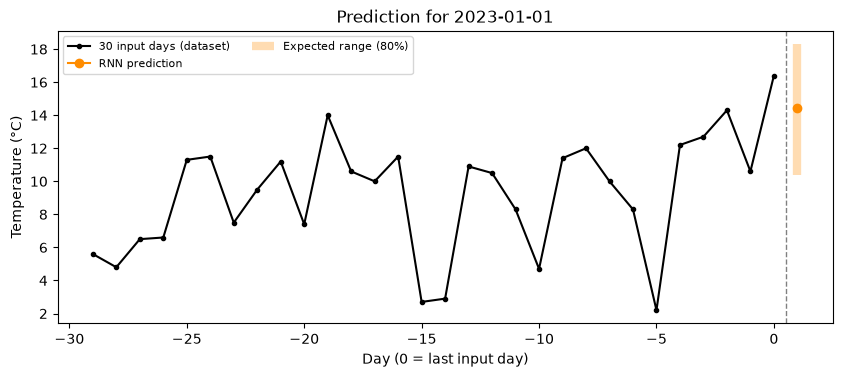

In [73]:
last_date = df["date"].iloc[-1]
first_target = df["date"].iloc[WINDOW]

def read_target_date():
    print(f"Dataset covers {df['date'].iloc[0].date()} to {last_date.date()}.")
    print(f"Enter a date from {first_target.date()} to {(last_date + pd.Timedelta(days=MAX_H)).date()} (YYYY-MM-DD).")
    print("Press Enter on its own to predict the day after the dataset ends.")
    for attempt in range(3):
        raw = input("Date to predict: ").strip()
        if raw == "":
            return last_date + pd.Timedelta(days=1)
        try:
            d = pd.Timestamp(raw)
        except ValueError:
            print("Please use the format YYYY-MM-DD, for example 2022-07-15. Try again.")
            continue
        if d < first_target or d > last_date + pd.Timedelta(days=MAX_H):
            print("That date is outside the allowed range. Try again.")
            continue
        return d
    raise SystemExit("Too many invalid attempts. Run the cell again.")

target_date = read_target_date()

if target_date <= last_date:                                   # date inside the dataset: evaluate against the real value
    i = int(df.index[df["date"] == target_date][0])
    window_temps = temps[i - WINDOW:i]
    days_ahead, actual = 1, float(temps[i])
    split = "training" if i < train_end else "validation" if i < val_end else "test"
    print(f"\nTarget {target_date.date()} is in the {split} period; using {df['date'].iloc[i - WINDOW].date()} to {df['date'].iloc[i - 1].date()} as input.")
    if split != "test":
        print("Note: the model saw this period during training or validation, so the result looks better than it would on new data.")
else:                                                          # date after the dataset: pure forecast
    window_temps = temps[-WINDOW:]
    days_ahead, actual = (target_date - last_date).days, None
    print(f"\nForecasting {target_date.date()} from the last 30 dataset days ({df['date'].iloc[-WINDOW].date()} to {last_date.date()}).")

result = forecast_from_temperatures(window_temps, days_ahead=days_ahead, actual=actual)
show_forecast(result, window_temps)

# Plot: the 30 input days, the predicted path and the expected range
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(range(-WINDOW + 1, 1), window_temps, "o-", ms=3, color="black", label="30 input days (dataset)")
steps = np.arange(1, days_ahead + 1)
ax.plot(steps, result["path"], "o-", color="darkorange", label="RNN prediction")
ax.vlines(days_ahead, result["range"][0], result["range"][1], color="darkorange", lw=6, alpha=0.3, label="Expected range (80%)")
if actual is not None:
    ax.plot([days_ahead], [actual], "g*", ms=14, label="Actual (dataset)")
ax.axvline(0.5, color="gray", ls="--", lw=1)
ax.set_xlabel("Day (0 = last input day)")
ax.set_ylabel("Temperature (°C)")
ax.set_title(f"Prediction for {target_date.date()}")
ax.legend(ncol=2, fontsize=8)
plt.show()





## Final summary

**Read 30 days one at a time → update the hidden state at each step → turn the final hidden state into tomorrow's temperature → compare honestly with simple baselines.**

The notebook explored the data, split it chronologically, scaled without leakage, built windows and baselines, wrote and gradient-checked an RNN from scratch, trained and evaluated it, looked inside the hidden state, tried multi-day forecasts, and ran controlled experiments.